Publication multi-panel figure saved to: /Users/macbookpro2020/niger-delta-phd/07_figures/06_conference_summary_panels.png


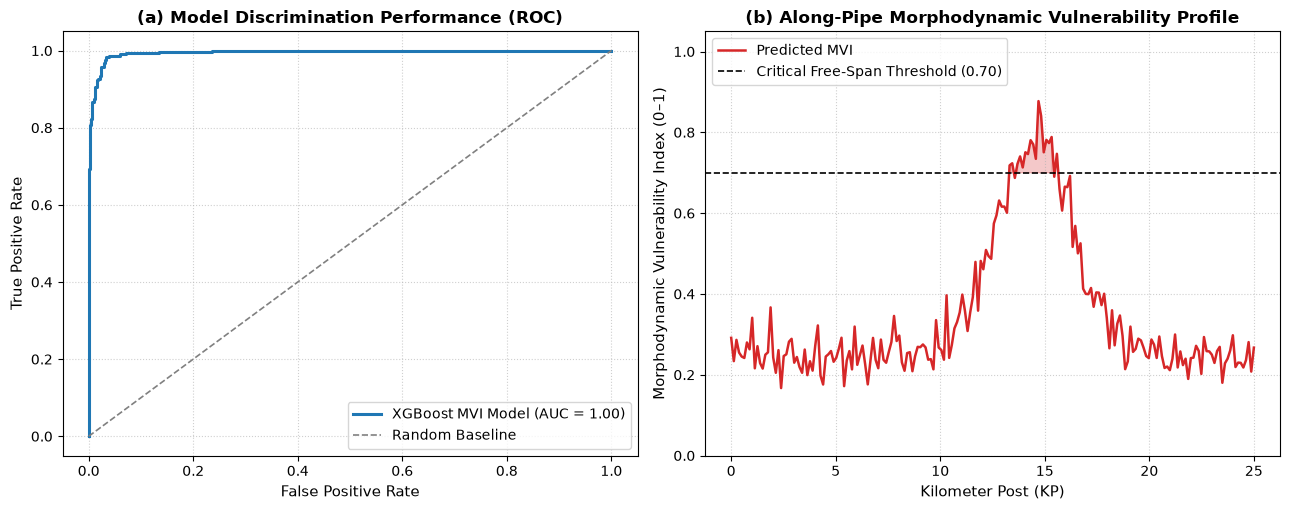

In [1]:
import os
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# 1. Load your saved XGBoost model from 06_models
home_path = os.path.expanduser("~")
model_path = os.path.join(home_path, "niger-delta-phd", "06_models", "xgboost_mvi_template.json")
loaded_model = xgb.XGBClassifier()
loaded_model.load_model(model_path)

# 2. Recreate the test evaluation set to plot the ROC Curve
np.random.seed(42)
n_samples = 1000
data = pd.DataFrame({
    'current_speed_ms': np.random.uniform(0.1, 1.8, n_samples),
    'slope_deg': np.random.uniform(0.0, 15.0, n_samples),
    'roughness_sri': np.random.uniform(0.01, 0.5, n_samples),
    'bcr_myr': np.random.normal(-0.05, 0.25, n_samples),
    'burial_depth_m': np.random.uniform(-0.5, 2.0, n_samples)
})
risk_score = (
    1.5 * data['current_speed_ms'] + 0.12 * data['slope_deg']
    - 2.0 * data['bcr_myr'] - 1.2 * data['burial_depth_m'] + np.random.normal(0, 0.4, n_samples)
)
y_true = (risk_score > np.percentile(risk_score, 70)).astype(int)
X = data

y_prob = loaded_model.predict_proba(X)[:, 1]
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

# 3. Simulate a 25 km Pipeline Corridor Profile (KP 0 to KP 25)
kp = np.linspace(0, 25, 200)
corridor_mvi = np.clip(0.25 + 0.55 * np.exp(-((kp - 14.5) ** 2) / 6.0) + np.random.normal(0, 0.04, 200), 0, 1)

# 4. Build Multi-Panel Publication Figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))

# Panel A: ROC Curve
ax1.plot(fpr, tpr, color='#1f77b4', lw=2.2, label=f'XGBoost MVI Model (AUC = {roc_auc:.2f})')
ax1.plot([0, 1], [0, 1], color='gray', lw=1.2, linestyle='--', label='Random Baseline')
ax1.set_title('(a) Model Discrimination Performance (ROC)', fontsize=12, fontweight='bold')
ax1.set_xlabel('False Positive Rate', fontsize=11)
ax1.set_ylabel('True Positive Rate', fontsize=11)
ax1.legend(loc='lower right', frameon=True)
ax1.grid(True, linestyle=':', alpha=0.6)

# Panel B: Corridor Risk Profile
ax2.plot(kp, corridor_mvi, color='#d62728', lw=1.8, label='Predicted MVI')
ax2.axhline(0.70, color='black', linestyle='--', lw=1.2, label='Critical Free-Span Threshold (0.70)')
ax2.fill_between(kp, 0.70, corridor_mvi, where=(corridor_mvi >= 0.70), color='#d62728', alpha=0.25)
ax2.set_title('(b) Along-Pipe Morphodynamic Vulnerability Profile', fontsize=12, fontweight='bold')
ax2.set_xlabel('Kilometer Post (KP)', fontsize=11)
ax2.set_ylabel('Morphodynamic Vulnerability Index (0–1)', fontsize=11)
ax2.set_ylim(0, 1.05)
ax2.legend(loc='upper left', frameon=True)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()

# 5. Save high-resolution figure to 07_figures
fig_out = os.path.join(home_path, "niger-delta-phd", "07_figures", "06_conference_summary_panels.png")
plt.savefig(fig_out, dpi=300, bbox_inches='tight')
print(f"Publication multi-panel figure saved to: {fig_out}")
plt.show()
